# Finish-turning deflection model, step by step
Every step of `turning_model.py` as its own cell, using plain NumPy (no module import until the last cell). Run top to bottom; edit only the inputs cell.

Units: mm, N, N/mm², rad. `ap` is a *radial* depth of cut, so the diameter drops by `2·ap`.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

# ---- Inputs ----
rc, f, ap_nom = 0.8, 0.18, 0.25     # nose radius, feed (mm/rev), nominal radial depth of cut (mm)
d, L = 16.0, 160.0                  # workpiece diameter and overhang length (mm)
k_machine = 50_000.0                # machine / tool-holder stiffness (N/mm)
vc = 60.0                           # cutting speed (m/min)
target_d = 15.5                     # desired final diameter (mm)

# Material: Al6061 (E from course AA6061 data, kc/kf fitted to course 7075 force data)
# Ti-6Al-4V homework set: E=114, kc1=4500, mc=-0.175, kf1=18250, mf=-0.611
E_GPa, kc1, mc, kf1, mf = 70.0, 2534.0, -0.149, 2126.0, -0.168

dkappa = 0.005                      # step along the nose arc (rad)
relax = 0.5                         # damping of the depth-of-cut iteration

## 1. Chip geometry
The nose arc engaged in the cut runs from `κmin` (set by the feed) to `κmax` (set by `ap`). The uncut chip thickness along it is

$$h(\kappa)=r_c+f\cos(\kappa-\tfrac{\pi}{2})-\sqrt{r_c^2+f^2\left(\cos^2(\kappa-\tfrac{\pi}{2})-1\right)}$$

engaged arc -6.45 to 46.57 deg, 186 points, ds = 4.00 um, max h = 140.3 um


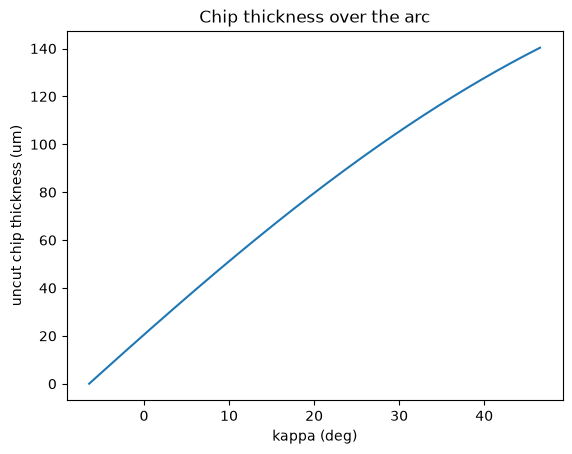

In [2]:
def arc(ap):
    """kappa grid, chip thickness h (mm) and arc length per element ds (mm) for a given ap."""
    k_min = -math.acos((rc - f**2 / (8 * rc)) / rc)
    k_max = math.acos((rc - ap) / rc)
    n = max(1, round((k_max - k_min) / dkappa))
    kappa = np.linspace(k_min, k_max, n + 1)
    c = np.cos(kappa - np.pi / 2)
    h = rc + f * c - np.sqrt(rc**2 + f**2 * (c**2 - 1))
    return kappa, np.maximum(h, 1e-9), rc * (k_max - k_min) / n

kappa, h, ds = arc(ap_nom)
print(f"engaged arc {math.degrees(kappa[0]):.2f} to {math.degrees(kappa[-1]):.2f} deg, "
      f"{len(kappa)} points, ds = {ds * 1000:.2f} um, max h = {h.max() * 1000:.1f} um")
plt.plot(np.degrees(kappa), h * 1000)
plt.xlabel("kappa (deg)"); plt.ylabel("uncut chip thickness (um)"); plt.title("Chip thickness over the arc")
plt.show()

## 2. Cutting forces
Specific forces follow power laws in the chip thickness (in µm): $k_c=k_{c1}h^{m_c}$, $k_f=k_{f1}h^{m_f}$. Each arc element contributes $dF_c=k_c\,h\,ds$ and $dF_f=k_f\,h\,ds$; the feed force acts normal to the cutting edge, so radial $=\cos\kappa\,dF_f$ and axial $=\sin\kappa\,dF_f$. Summing over the arc gives the forces.

nominal-ap forces:  Fc 73.9 N   Fradial 49.2 N   Faxial 25.5 N   h_avg 76.5 um


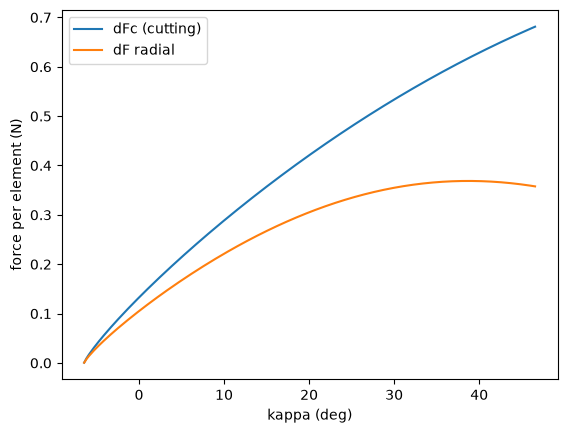

In [3]:
def forces(ap):
    """Return Fc, Fr, Fa (N) and mean chip thickness (mm) for a radial depth of cut ap."""
    if ap <= 1e-9:
        return 0.0, 0.0, 0.0, 0.0
    kappa, h, ds = arc(ap)
    h_um = h * 1000
    dFc = kc1 * h_um**mc * h * ds
    dFf = kf1 * h_um**mf * h * ds
    return dFc.sum(), (np.cos(kappa) * dFf).sum(), (np.sin(kappa) * dFf).sum(), h.mean()

Fc, Fr, Fa, h_avg = forces(ap_nom)
print(f"nominal-ap forces:  Fc {Fc:.1f} N   Fradial {Fr:.1f} N   Faxial {Fa:.1f} N   h_avg {h_avg * 1000:.1f} um")

# Where along the arc the force is generated
kappa, h, ds = arc(ap_nom)
dFc = kc1 * (h * 1000)**mc * h * ds
dFr = np.cos(kappa) * kf1 * (h * 1000)**mf * h * ds
plt.plot(np.degrees(kappa), dFc, label="dFc (cutting)")
plt.plot(np.degrees(kappa), dFr, label="dF radial")
plt.xlabel("kappa (deg)"); plt.ylabel("force per element (N)"); plt.legend(); plt.show()

## 3. Beam and machine compliance (Part 1)
The workpiece is a cantilever with the radial force at its free end: $\delta_{beam}=\dfrac{F L^3}{3EI}$, $I=\dfrac{\pi d^4}{64}$. The machine and tool holder add a series spring, $\delta_{machine}=F/k$. Compliance is deflection per newton.

In [4]:
E = E_GPa * 1000                    # N/mm^2
I = math.pi * d**4 / 64             # mm^4
c_beam = L**3 / (3 * E * I)         # mm/N
c_mach = 1 / k_machine              # mm/N
print(f"I = {I:.0f} mm^4   beam stiffness {1 / c_beam:.0f} N/mm   machine stiffness {k_machine:.0f} N/mm")
print(f"compliance: beam {c_beam * 1000:.2f} um/N   machine {c_mach * 1000:.3f} um/N")

# Part 1 on its own: tip deflection for a few point loads
print("\n load [N]  tip deflection [um]")
for F in (10, 25, 50, 100):
    print(f"{F:>8}  {F * (c_beam + c_mach) * 1000:>18.1f}")

I = 3217 mm^4   beam stiffness 165 N/mm   machine stiffness 50000 N/mm
compliance: beam 6.06 um/N   machine 0.020 um/N

 load [N]  tip deflection [um]
      10                60.8
      25               152.1
      50               304.2
     100               608.3


## 4. One pass: how much does the bar deflect?
Using the nominal depth of cut, the radial force pushes the bar away by $\delta$, so only $a_{p,true}=a_{p,nom}-\delta$ is actually removed.

In [5]:
delta = Fr * (c_beam + c_mach)
print(f"deflection {delta * 1000:.1f} um -> ap after one pass = {max(ap_nom - delta, 0):.4f} mm "
      f"(nominal {ap_nom} mm; a negative result is clamped to 0)")
print("This first guess overshoots, because it uses the force at the full nominal depth: iterate next.")

deflection 299.5 um -> ap after one pass = 0.0000 mm (nominal 0.25 mm; a negative result is clamped to 0)
This first guess overshoots, because it uses the force at the full nominal depth: iterate next.


## 5. Iterate to the true depth of cut
A smaller true depth of cut means a smaller force and so less deflection, which changes the true depth of cut again. We repeat until it stops changing (a fixed point). `relax = 0.5` damps the update so it settles quickly; the course workbook (`relax = 1`) oscillates towards the same answer.

pass  deflection [um]  % of nominal ap
   1            299.5            120%
   2            190.0             76%
   3            155.0             62%
   4            156.4             63%
   5            156.4             63%
   6            156.4             63%

true ap = 0.0936 mm (37% of nominal)


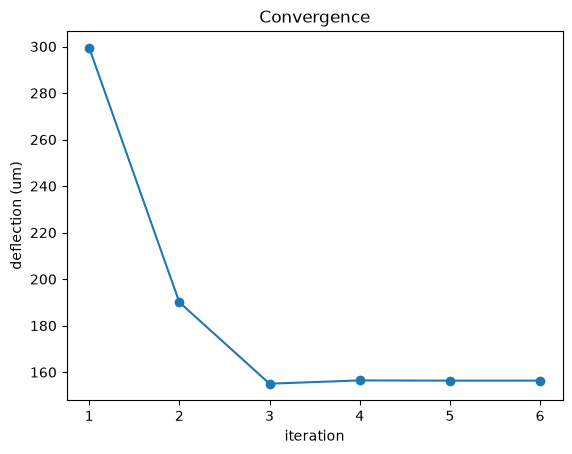

In [6]:
def solve_true_ap(ap_nominal, relax=relax, max_iter=200, tol=1e-6):
    ap, history = ap_nominal, []
    for _ in range(max_iter):
        delta = forces(ap)[1] * (c_beam + c_mach)
        history.append(delta)
        new = ap + relax * (max(ap_nominal - delta, 0.0) - ap)
        done = abs(new - ap) < tol
        ap = new
        if done:
            break
    return ap, history

ap_true, history = solve_true_ap(ap_nom)
print("pass  deflection [um]  % of nominal ap")
for i, dl in enumerate(history, 1):
    print(f"{i:>4}  {dl * 1000:>15.1f}  {dl / ap_nom:>14.0%}")
print(f"\ntrue ap = {ap_true:.4f} mm ({ap_true / ap_nom:.0%} of nominal)")
plt.plot(range(1, len(history) + 1), np.array(history) * 1000, "o-")
plt.xlabel("iteration"); plt.ylabel("deflection (um)"); plt.title("Convergence"); plt.show()

## 6. Final diameter
`ap` is radial, so the diameter falls by `2·ap`. Deflection leaves extra material behind.

In [7]:
d_zero = d - 2 * ap_nom
d_final = d - 2 * ap_true
print(f"zero-deflection diameter {d_zero:.4f} mm")
print(f"predicted diameter       {d_final:.4f} mm  (oversize {(d_final - d_zero) * 1000:.1f} um)")

zero-deflection diameter 15.5000 mm
predicted diameter       15.8127 mm  (oversize 312.7 um)


## 7. What nominal depth of cut gives the target diameter?
Command more than you want, by exactly what the tool fails to remove: $a_{nom}\leftarrow a_{nom}+(a_{target}-a_{true})$ until they agree.

In [8]:
ap_target = (d - target_d) / 2
ap_cmd = ap_target
print("step  commanded ap  true ap   error [um]")
for step in range(1, 51):
    ap_t, _ = solve_true_ap(ap_cmd)
    err = ap_target - ap_t
    print(f"{step:>4}  {ap_cmd:>12.4f}  {ap_t:>7.4f}  {err * 1000:>10.2f}")
    if abs(err) < 1e-5:
        break
    ap_cmd += err
print(f"\ncommand ap = {ap_cmd:.4f} mm to reach diameter {target_d} mm")

step  commanded ap  true ap   error [um]
   1        0.2500   0.0936      156.36
   2        0.4064   0.1715       78.48
   3        0.4848   0.2137       36.29
   4        0.5211   0.2339       16.09
   5        0.5372   0.2430        6.99
   6        0.5442   0.2470        3.01
   7        0.5472   0.2487        1.29
   8        0.5485   0.2494        0.55
   9        0.5491   0.2498        0.24
  10        0.5493   0.2499        0.10
  11        0.5494   0.2500        0.04
  12        0.5495   0.2500        0.02
  13        0.5495   0.2500        0.01

command ap = 0.5495 mm to reach diameter 15.5 mm


## 8. True vs nominal depth of cut

nominal ap [mm]  true ap [mm]  lost [%]
          0.050        0.0102       80%
          0.100        0.0284       72%
          0.150        0.0488       67%
          0.200        0.0707       65%
          0.250        0.0936       63%
          0.300        0.1176       61%
          0.350        0.1425       59%
          0.400        0.1682       58%
          0.450        0.1947       57%
          0.500        0.2221       56%


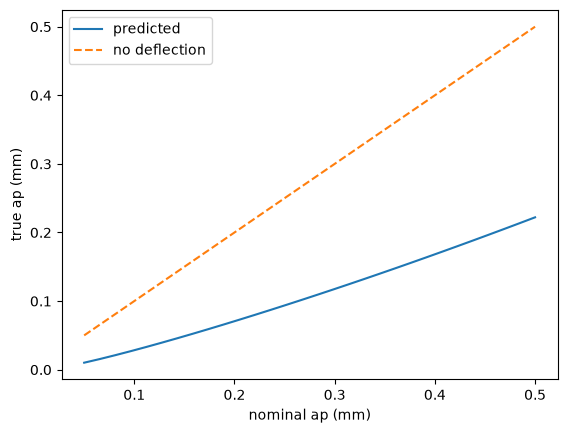

In [9]:
noms = np.linspace(0.05, 0.5, 10)
trues = [solve_true_ap(a)[0] for a in noms]
print("nominal ap [mm]  true ap [mm]  lost [%]")
for a, t in zip(noms, trues):
    print(f"{a:>15.3f}  {t:>12.4f}  {1 - t / a:>8.0%}")
xs = np.linspace(0.05, 0.5, 30)
plt.plot(xs, [solve_true_ap(a)[0] for a in xs], label="predicted")
plt.plot(xs, xs, "--", label="no deflection")
plt.xlabel("nominal ap (mm)"); plt.ylabel("true ap (mm)"); plt.legend(); plt.show()

## 9. Other outputs
Spindle speed, torque and power at the converged cut, and the kinematic roughness $R_a=\dfrac{f^2}{32 r_c}\cdot\dfrac{4}{3}$ (the course workbook's 4/3 factor).

In [10]:
Fc_true, Fr_true, Fa_true, h_true = forces(ap_true)
rpm = 1000 * vc / (math.pi * d)
torque = Fc_true * d / 2 / 1000
power = torque * 2 * math.pi * rpm / 60
Ra = f**2 / (32 * rc) * 1000 * 4 / 3
print(f"forces at true ap: Fc {Fc_true:.1f} N  Fr {Fr_true:.1f} N  Fa {Fa_true:.1f} N")
print(f"rpm {rpm:.0f}   torque {torque:.2f} N*m   power {power:.0f} W   kinematic Ra {Ra:.2f} um")
print(f"deflection / mean chip thickness = {(Fr_true * (c_beam + c_mach)) / h_true:.0%} "
      "(> 10% suggests chatter risk)")

forces at true ap: Fc 34.8 N  Fr 25.7 N  Fa 7.3 N
rpm 1194   torque 0.28 N*m   power 35 W   kinematic Ra 1.69 um
deflection / mean chip thickness = 299% (> 10% suggests chatter risk)


## 10. Check against `turning_model.py`
The module is the same model as functions; the two should agree.

In [11]:
import turning_model as tm

p = dict(rc=rc, f=f, ap=ap_nom, d=d, L=L, k_machine=k_machine, vc=vc)
mat = dict(name="notebook", E_GPa=E_GPa, kc1=kc1, mc=mc, kf1=kf1, mf=mf)
res = tm.solve_deflection(p, mat, relax=relax)
ap_cmd_mod, _ = tm.solve_nominal_ap(p, mat, target_d)
print(f"true ap   notebook {ap_true:.6f}   module {res['ap_true']:.6f}")
print(f"command ap notebook {ap_cmd:.6f}   module {ap_cmd_mod:.6f}")
assert abs(ap_true - res["ap_true"]) < 1e-5 and abs(ap_cmd - ap_cmd_mod) < 1e-4

true ap   notebook 0.093643   module 0.093643
command ap notebook 0.549481   module 0.549481
